In [ ]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

# Paleta de cores do projeto (uma cor fixa para cada município e para cada taxa)
CORES_MUNICIPIOS = {
    "RIO DE JANEIRO": "#D55E00",  # laranja-avermelhado
    "SÃO GONÇALO": "#0072B2",     # azul
    "NITERÓI": "#009E73",         # verde
    "MARICÁ": "#CC79A7",          # rosa
}
CORES_TAXAS = {
    "Abandono": "#D62828",    # vermelho
    "Reprovação": "#F77F00",  # laranja
    "Aprovação": "#2A9D8F",   # verde-azulado
}


In [ ]:
import os

ARQUIVO = 'tabela_final.csv'
ID_TABELA_FINAL = '13ZcWd_wD4lIFMPi_YI0ba0xjUCMTr4tb'  # tabela_final.csv no Drive do projeto

# Se a tabela não estiver na sessão, baixa direto do Google Drive
# (na primeira vez o Colab pede autorização da conta Google)
if not os.path.exists(ARQUIVO):
    from google.colab import auth
    from googleapiclient.discovery import build
    from googleapiclient.http import MediaIoBaseDownload

    auth.authenticate_user()
    servico = build('drive', 'v3')
    pedido = servico.files().get_media(fileId=ID_TABELA_FINAL)

    with open(ARQUIVO, 'wb') as f:
        baixador = MediaIoBaseDownload(f, pedido)
        concluido = False
        while not concluido:
            _, concluido = baixador.next_chunk()

df = pd.read_csv(ARQUIVO)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4009 entries, 0 to 4008
Data columns (total 8 columns):
 #   Column                                   Non-Null Count  Dtype  
---  ------                                   --------------  -----  
 0   Ano_do_Censo                             4009 non-null   int64  
 1   Nome_do_Municipio                        4009 non-null   object 
 2   Codigo_da_Escola                         4009 non-null   int64  
 3   Nome_da_Escola                           4009 non-null   object 
 4   Quantidade_de_Matriculados_Ensino_Medio  4009 non-null   float64
 5   Aprovacao_EM_Total                       4009 non-null   float64
 6   Reprovacao_EM_Total                      4009 non-null   float64
 7   Abandono_EM_Total                        4009 non-null   float64
dtypes: float64(4), int64(2), object(2)
memory usage: 250.7+ KB


In [ ]:
#checando se há valores nulos
df.isna().sum()

,0
Ano_do_Censo,0
Nome_do_Municipio,0
Codigo_da_Escola,0
Nome_da_Escola,0
Quantidade_de_Matriculados_Ensino_Medio,0
Aprovacao_EM_Total,0
Reprovacao_EM_Total,0
Abandono_EM_Total,0


In [ ]:
#checando se há duplicatas
df.duplicated().sum()

np.int64(0)

In [ ]:
#checando os valores únicos
df['Ano_do_Censo'].unique()


array([2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2015, 2016, 2025])

In [ ]:
colunas_numericas = ["Quantidade_de_Matriculados_Ensino_Medio", "Aprovacao_EM_Total", "Reprovacao_EM_Total", "Abandono_EM_Total"]
df[colunas_numericas].describe()

,Quantidade_de_Matriculados_Ensino_Medio,Aprovacao_EM_Total,Reprovacao_EM_Total,Abandono_EM_Total
count,4009.000000,4009.000000,4009.000000,4009.000000
mean,513.982040,77.664405,14.790422,7.545173
std,520.913534,13.176567,9.987367,8.331654
min,2.000000,0.000000,0.000000,0.000000
25%,162.000000,68.500000,7.200000,0.700000
50%,294.000000,77.900000,14.100000,5.200000
75%,671.000000,87.600000,20.800000,11.500000
max,2805.000000,100.000000,80.600000,100.000000


## Outliers

**Outlier** é um valor muito diferente da maioria. Pode ser um erro de registro ou uma situação real e rara.
Usamos dois métodos:

**a) Boxplot / IQR (intervalo interquartil)**
- IQR = Q3 − Q1 (a "caixa" do boxplot, onde estão os 50% do meio)
- É outlier quem estiver **abaixo de Q1 − 1,5 × IQR** ou **acima de Q3 + 1,5 × IQR**

**b) Z-score**
- z = (valor − média) / desvio padrão
- Diz **quantos desvios padrão** o valor está longe da média
- Usamos a regra comum: é outlier se **|z| > 3**

###Boxplot

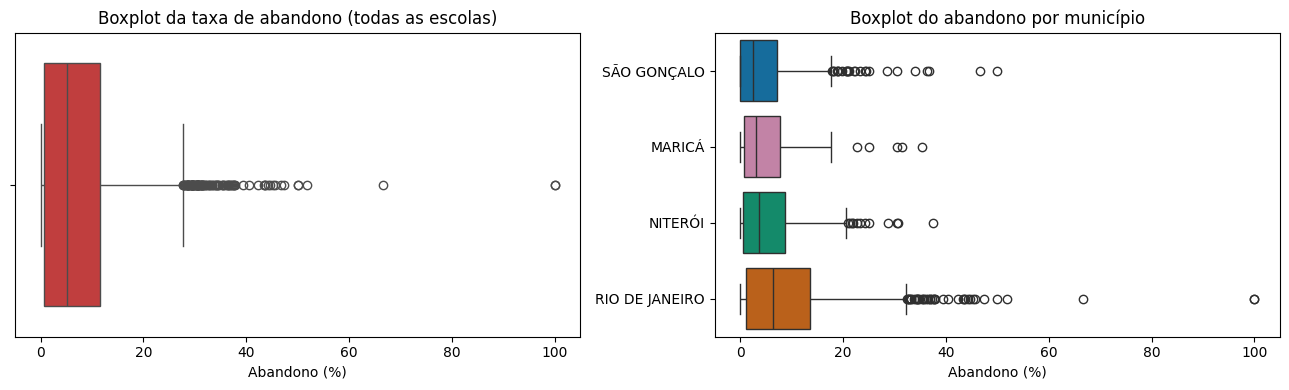

In [ ]:
# Boxplot geral e por município
fig, eixos = plt.subplots(1, 2, figsize=(13, 4))

sns.boxplot(x=df["Abandono_EM_Total"], ax=eixos[0], color=CORES_TAXAS["Abandono"])
eixos[0].set_title("Boxplot da taxa de abandono (todas as escolas)")
eixos[0].set_xlabel("Abandono (%)")

sns.boxplot(data=df, x="Abandono_EM_Total", y="Nome_do_Municipio", ax=eixos[1],
            hue="Nome_do_Municipio", palette=CORES_MUNICIPIOS, legend=False)
eixos[1].set_title("Boxplot do abandono por município")
eixos[1].set_xlabel("Abandono (%)")
eixos[1].set_ylabel("")

plt.tight_layout()
plt.savefig("boxplot_abandono.png", dpi=150, bbox_inches="tight")
plt.show()

Os pontos isolados à direita das caixas são os outliers pelo critério do boxplot.

In [49]:
# a) Método IQR
q1 = df["Abandono_EM_Total"].quantile(0.25)
q3 = df["Abandono_EM_Total"].quantile(0.75)
iqr = q3 - q1
limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

outliers_iqr = df[(df["Abandono_EM_Total"] < limite_inferior) | (df["Abandono_EM_Total"] > limite_superior)]

print(f"Q1 = {q1:.1f}%   Q3 = {q3:.1f}%   IQR = {iqr:.1f}")
print(f"Limite superior = {limite_superior:.1f}%  (limite inferior = {limite_inferior:.1f}%, negativo, então não existe na prática)")
print(f"Outliers pelo IQR: {len(outliers_iqr)} registros ({len(outliers_iqr) / len(df):.1%} da base)")

Q1 = 0.7%   Q3 = 11.5%   IQR = 10.8
Limite superior = 27.7%  (limite inferior = -15.5%, negativo, então não existe na prática)
Outliers pelo IQR: 101 registros (2.5% da base)


###Z-score

In [53]:
from scipy.stats import zscore

# b) Método Z-score
df["Abandono_zscore"] = zscore(
    df["Abandono_EM_Total"],
    ddof=1
)

outliers_z = df[df["Abandono_zscore"].abs() > 3]

print(f"Outliers pelo z-score (|z| > 3): {len(outliers_z)} registros ({len(outliers_z) / len(df):.1%} da base)")

print(f"Ou seja, abandono acima de {df['Abandono_EM_Total'].mean() + 3 * df['Abandono_EM_Total'].std():.1f}%")

Outliers pelo z-score (|z| > 3): 45 registros (1.1% da base)
Ou seja, abandono acima de 32.5%


In [54]:
# Os 10 casos mais extremos
outliers_z.sort_values("Abandono_EM_Total", ascending=False)[
    ["Ano_do_Censo", "Nome_do_Municipio", "Nome_da_Escola", "Quantidade_de_Matriculados_Ensino_Medio", "Aprovacao_EM_Total", "Reprovacao_EM_Total", "Abandono_EM_Total"]
].head(10).round(2)

,Ano_do_Censo,Nome_do_Municipio,Nome_da_Escola,Quantidade_de_Matriculados_Ensino_Medio,Aprovacao_EM_Total,Reprovacao_EM_Total,Abandono_EM_Total
3343,2016,RIO DE JANEIRO,ESCOLA TECNICA ESTADUAL ADOLPHO BLOCH,868.0,0.0,0.0,100.0
3354,2016,RIO DE JANEIRO,ESCOLA TECNICA ESTADUAL SANTA CRUZ,1182.0,0.0,0.0,100.0
3300,2017,RIO DE JANEIRO,CE LUIZA MAHIN,3.0,33.3,0.0,66.7
577,2025,RIO DE JANEIRO,CE CASTELNUOVO,110.0,48.2,0.0,51.8
2413,2017,SÃO GONÇALO,CIEP BRIZOLAO 440 MAJOR JOAQUIM DE AZEREDO COU...,2.0,50.0,0.0,50.0
3903,2015,RIO DE JANEIRO,CE MARIA MONTESSORI,20.0,50.0,0.0,50.0
622,2022,RIO DE JANEIRO,CE NILO PECANHA,99.0,49.5,3.1,47.4
2948,2016,SÃO GONÇALO,CIEP 423 MORA GUIMARAES,17.0,53.3,0.0,46.7
574,2022,RIO DE JANEIRO,CE CASTELNUOVO,115.0,38.1,16.2,45.7
417,2019,RIO DE JANEIRO,CE CUBA,247.0,52.0,2.8,45.2


In [55]:
# Em quais municípios e anos estão os outliers (z-score)?
pd.crosstab(outliers_z["Ano_do_Censo"], outliers_z["Nome_do_Municipio"])

Nome_do_Municipio,MARICÁ,NITERÓI,RIO DE JANEIRO,SÃO GONÇALO
Ano_do_Censo,,,,
2015,0,0,2,1
2016,0,1,15,1
2017,0,0,1,1
2018,0,0,5,0
2019,0,0,5,0
2020,0,0,1,0
2022,0,0,5,1
2023,1,0,0,1
2024,0,0,3,0


**Leitura:**
- O z-score é mais rígido (menos outliers) que o IQR.
- A maioria dos outliers está no **Rio de Janeiro** e em **2016**.
- Há dois casos com **100% de abandono** em 2016 (duas escolas técnicas estaduais com centenas de alunos e
  0% de aprovação). Isso é muito provavelmente **erro de registro** ou efeito da greve/ocupação daquele ano.
- Também há escolas com pouquíssimos alunos (2 ou 3), em que 1 aluno que sai já vira 33% ou 50% de abandono.

**Decisão:** não apagamos os outliers da base, porque muitos são reais.

In [ ]:
# Z-score de todas as variáveis numéricas (quantos outliers cada uma tem)
for coluna in colunas_numericas:
    z = (df[coluna] - df[coluna].mean()) / df[coluna].std()
    print(f"{coluna:13s}: {(z.abs() > 3).sum():3d} outliers (|z| > 3)")

Quantidade_de_Matriculados_Ensino_Medio:  76 outliers (|z| > 3)
Aprovacao_EM_Total:  11 outliers (|z| > 3)
Reprovacao_EM_Total:  34 outliers (|z| > 3)
Abandono_EM_Total:  45 outliers (|z| > 3)


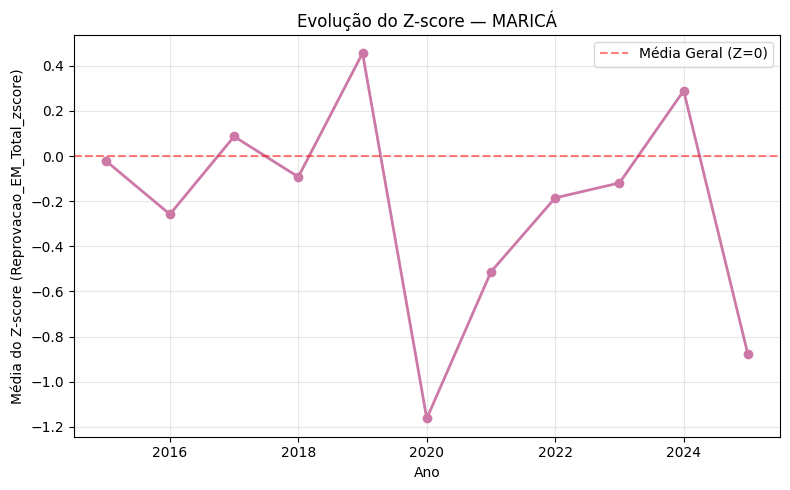

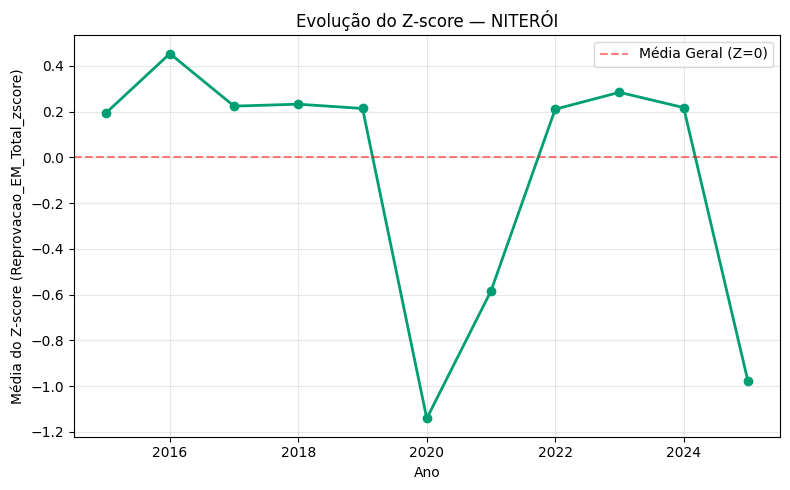

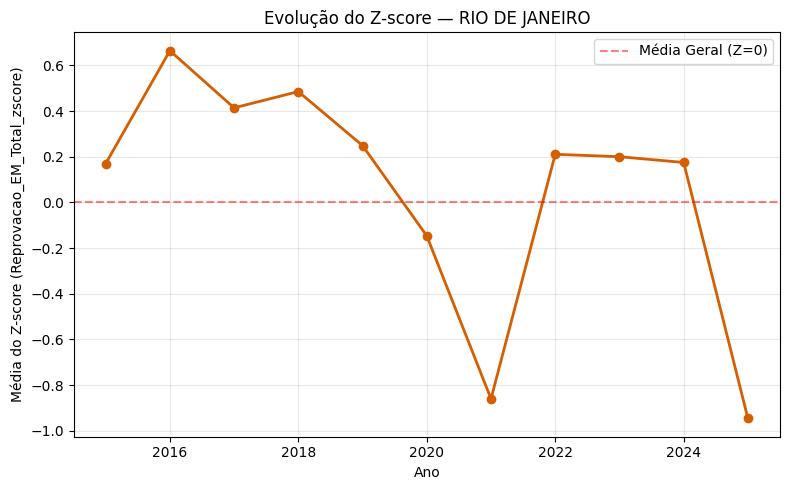

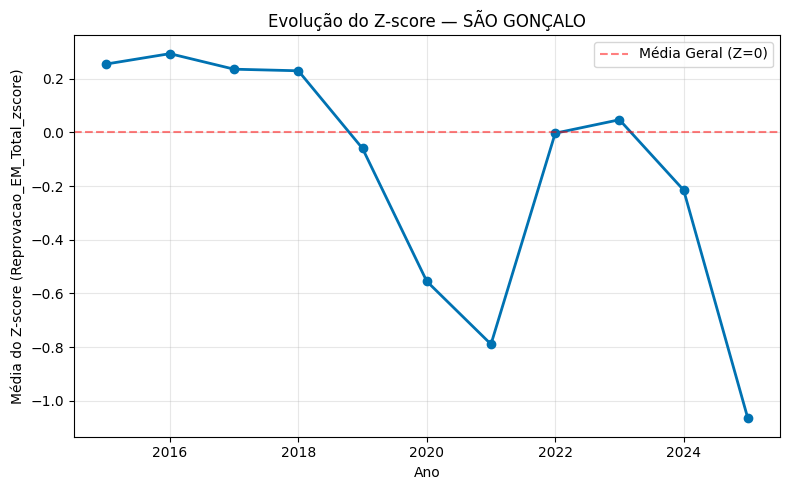

In [50]:
import pandas as pd
import matplotlib.pyplot as plt


colunas_numericas = df.select_dtypes(include=['number'])

# Calcular Z-scores e renomear colunas
zscores = (colunas_numericas - colunas_numericas.mean()) / colunas_numericas.std()
zscores.columns = [f"{col}_zscore" for col in zscores.columns]

# Juntar ao DataFrame original criando a variável exata que o erro apontou
teste_com_zscore = pd.concat([df, zscores], axis=1)


#GERAR OS GRÁFICOS

colunas_zscore = [col for col in teste_com_zscore.columns if col.endswith('_zscore')]

variavel_zscore = colunas_zscore[5]

# Agrupar por Município e Ano
colunas_selecionadas = ['Nome_do_Municipio', 'Ano_do_Censo', variavel_zscore]

zscore_ano_municipio = (
    teste_com_zscore[colunas_selecionadas]
    .groupby(['Nome_do_Municipio', 'Ano_do_Censo'])
    .mean()
    .reset_index()
)

# Escolher os primeiros 5 municípios para teste
municipios_alvo = zscore_ano_municipio["Nome_do_Municipio"].unique()[:5]

# Plotar
for municipio in municipios_alvo:
    dados_municipio = zscore_ano_municipio[
        zscore_ano_municipio["Nome_do_Municipio"] == municipio
    ].sort_values("Ano_do_Censo")

    plt.figure(figsize=(8, 5))

    plt.plot(
        dados_municipio["Ano_do_Censo"],
        dados_municipio[variavel_zscore],
        marker="o",
        color=CORES_MUNICIPIOS[municipio],
        linewidth=2
    )

    plt.axhline(y=0, color='red', linestyle='--', alpha=0.5, label='Média Geral (Z=0)')

    plt.xlabel("Ano")
    plt.ylabel(f"Média do Z-score ({variavel_zscore})")
    plt.title(f"Evolução do Z-score — {municipio}")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

#Outliers - Anos

###Boxplot

In [51]:
media_anual = (
    df.groupby('Ano_do_Censo')['Abandono_EM_Total']
    .mean()
    .reset_index()
)

media_anual = media_anual[
    media_anual['Ano_do_Censo'].between(2015, 2023)
]

display(media_anual)

,Ano_do_Censo,Abandono_EM_Total
0,2015,7.714601
1,2016,13.020000
2,2017,7.467751
3,2018,8.020811
4,2019,10.891086
5,2020,0.602479
6,2021,2.939118
7,2022,9.836364
8,2023,8.336639


In [ ]:
Q1 = media_anual['Abandono_EM_Total'].quantile(0.25)
Q3 = media_anual['Abandono_EM_Total'].quantile(0.75)

IQR = Q3 - Q1

limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

print(f'Q1: {Q1:.4f}')
print(f'Q3: {Q3:.4f}')
print(f'IQR: {IQR:.4f}')
print(f'Limite inferior: {limite_inferior:.4f}')
print(f'Limite superior: {limite_superior:.4f}')

Q1: 7.4678
Q3: 9.8364
IQR: 2.3686
Limite inferior: 3.9148
Limite superior: 13.3893


In [ ]:
media_anual['Outlier'] = (
    (media_anual['Abandono_EM_Total'] < limite_inferior) |
    (media_anual['Abandono_EM_Total'] > limite_superior)
)

display(media_anual)

,Ano_do_Censo,Abandono_EM_Total,Outlier
0,2015,7.714601,False
1,2016,13.020000,False
2,2017,7.467751,False
3,2018,8.020811,False
4,2019,10.891086,False
5,2020,0.602479,True
6,2021,2.939118,True
7,2022,9.836364,False
8,2023,8.336639,False


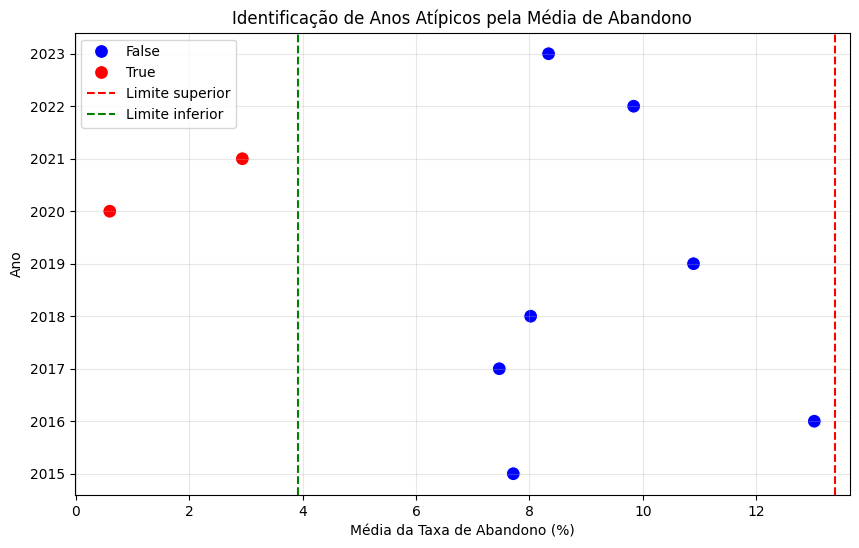

In [ ]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=media_anual,
    x='Abandono_EM_Total',
    y='Ano_do_Censo',
    hue='Outlier',
    palette={True: 'red', False: 'blue'},
    s=100
)

plt.axvline(
    limite_superior,
    color='red',
    linestyle='--',
    label='Limite superior'
)

plt.axvline(
    limite_inferior,
    color='green',
    linestyle='--',
    label='Limite inferior'
)

plt.title('Identificação de Anos Atípicos pela Média de Abandono')
plt.xlabel('Média da Taxa de Abandono (%)')
plt.ylabel('Ano')
plt.legend()
plt.grid(alpha=0.3)
plt.savefig('outliers_anos.png', dpi=150, bbox_inches='tight')
plt.show()

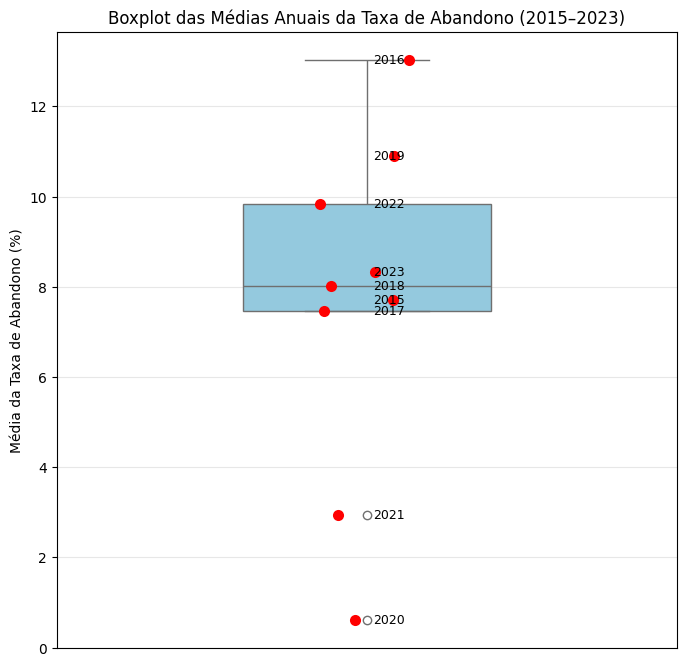

In [52]:
plt.figure(figsize=(8, 8))

sns.boxplot(
    y=media_anual['Abandono_EM_Total'],
    color='skyblue',
    width=0.4
)

sns.stripplot(
    y=media_anual['Abandono_EM_Total'],
    color='red',
    size=8
)

for _, linha in media_anual.iterrows():
    plt.text(
        0.01,
        linha['Abandono_EM_Total'],
        str(int(linha['Ano_do_Censo'])),
        fontsize=9,
        va='center'
    )

plt.title('Boxplot das Médias Anuais da Taxa de Abandono (2015–2023)')
plt.ylabel('Média da Taxa de Abandono (%)')
plt.xticks([])
plt.grid(axis='y', alpha=0.3)
plt.savefig('boxplot_anos.png', dpi=150, bbox_inches='tight')
plt.show()

###Z-score

In [37]:
from scipy.stats import zscore

media_anual['Z_score'] = zscore(
    media_anual['Abandono_EM_Total'],
    ddof=0
)

display(media_anual)

,Ano_do_Censo,Abandono_EM_Total,Outlier,Z_score
0,2015,7.714601,False,0.018598
1,2016,13.020000,False,1.492396
2,2017,7.467751,False,-0.049975
3,2018,8.020811,False,0.103661
4,2019,10.891086,False,0.901001
5,2020,0.602479,True,-1.957093
6,2021,2.939118,True,-1.307993
7,2022,9.836364,False,0.608007
8,2023,8.336639,False,0.191396


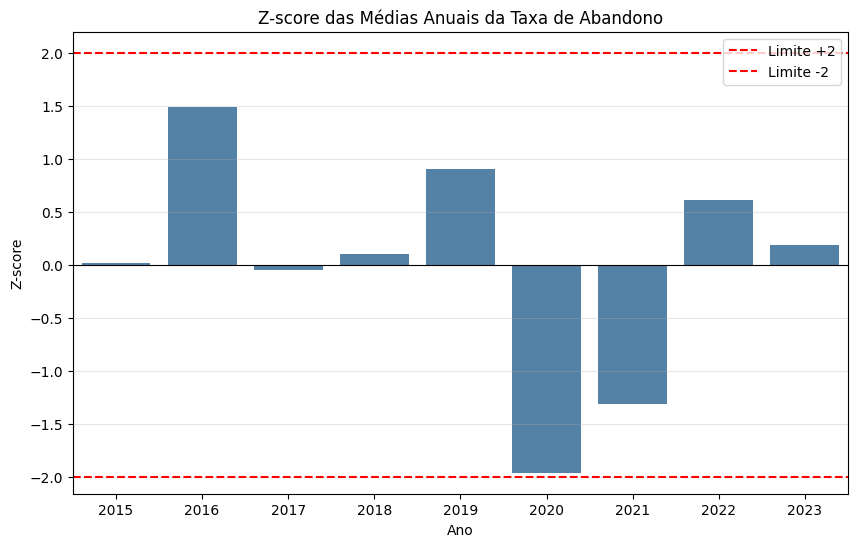

In [48]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=media_anual,
    x='Ano_do_Censo',
    y='Z_score',
    hue='Outlier_Zscore',
    palette={True: 'red', False: 'steelblue'},
    legend=False
)

plt.axhline(2, color='red', linestyle='--', label='Limite +2')
plt.axhline(-2, color='red', linestyle='--', label='Limite -2')
plt.axhline(0, color='black', linewidth=0.8)

plt.title('Z-score das Médias Anuais da Taxa de Abandono')
plt.xlabel('Ano')
plt.ylabel('Z-score')
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.savefig('zscore_anos.png', dpi=150, bbox_inches='tight')
plt.show()

##Gráficos

In [ ]:
abandono_municipio = (
    df.groupby('Nome_do_Municipio')['Abandono_EM_Total']
    .mean()
    .sort_values(ascending=False)
    .reset_index()
)



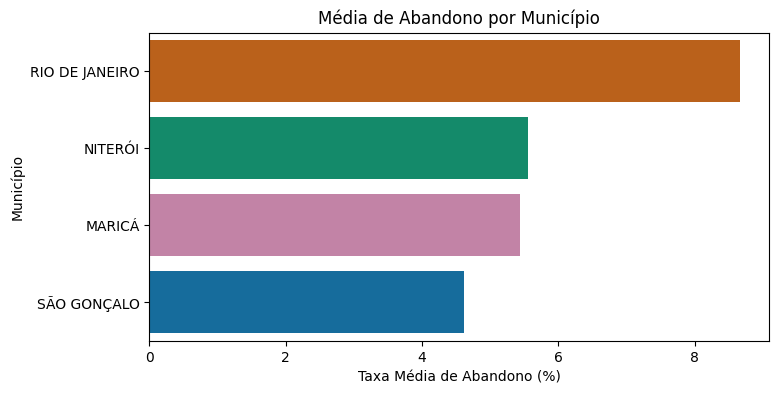

In [ ]:
#gráfico de média de abandono por município
plt.figure(figsize=(8, 4))
sns.barplot(
    data=abandono_municipio,
    y='Nome_do_Municipio',
    x='Abandono_EM_Total',
    hue='Nome_do_Municipio',
    palette=CORES_MUNICIPIOS,
    legend=False)
plt.title('Média de Abandono por Município')
plt.xlabel('Taxa Média de Abandono (%)')
plt.ylabel('Município')
plt.show()

In [ ]:
abandono_por_ano = (
    df.groupby('Ano_do_Censo')['Abandono_EM_Total']
      .mean()
      .reset_index()
)
display(abandono_por_ano)

,Ano_do_Censo,Abandono_EM_Total
0,2015,7.714601
1,2016,13.020000
2,2017,7.467751
3,2018,8.020811
4,2019,10.891086
5,2020,0.602479
6,2021,2.939118
7,2022,9.836364
8,2023,8.336639
9,2024,8.182337


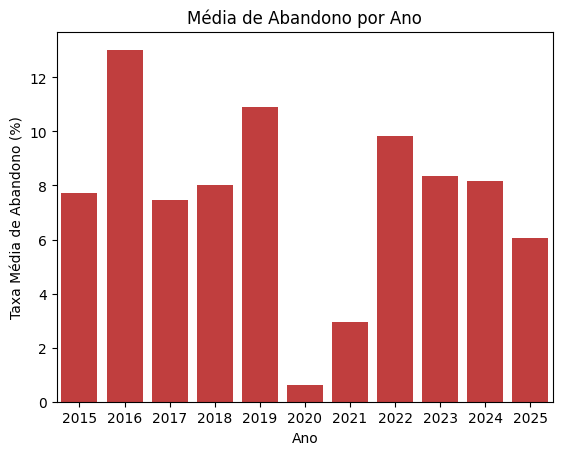

In [ ]:
#média de abandono por ano
sns.barplot(abandono_por_ano, x='Ano_do_Censo', y='Abandono_EM_Total', color=CORES_TAXAS['Abandono'])
plt.title('Média de Abandono por Ano')
plt.xlabel('Ano')
plt.ylabel('Taxa Média de Abandono (%)')
plt.show()

In [ ]:
aprovacao_por_ano = (
    df.groupby('Ano_do_Censo')['Aprovacao_EM_Total']
      .mean()
      .reset_index()
)
display(aprovacao_por_ano)

,Ano_do_Censo,Aprovacao_EM_Total
0,2015,75.681818
1,2016,66.609167
2,2017,74.187534
3,2018,73.178378
4,2019,72.383287
5,2020,88.072727
6,2021,90.367218
7,2022,73.779339
8,2023,75.171350
9,2024,75.929076


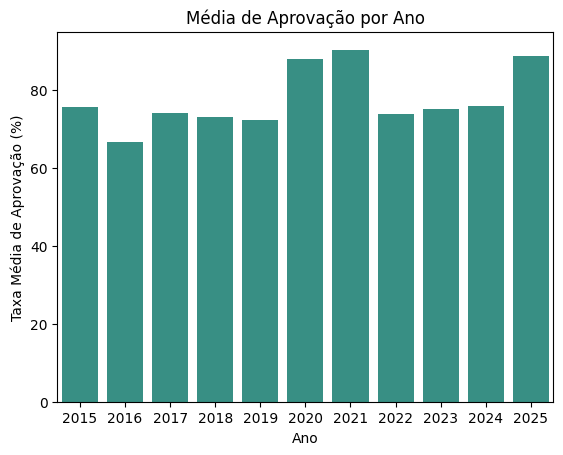

In [ ]:
#média de aprovação por ano
sns.barplot(aprovacao_por_ano, x='Ano_do_Censo', y='Aprovacao_EM_Total', color=CORES_TAXAS['Aprovação'])
plt.title('Média de Aprovação por Ano')
plt.xlabel('Ano')
plt.ylabel('Taxa Média de Aprovação (%)')
plt.show()

In [ ]:
#checando quantos registros temos por município
df['Nome_do_Municipio'].value_counts()

,count
Nome_do_Municipio,
RIO DE JANEIRO,2795
SÃO GONÇALO,729
NITERÓI,382
MARICÁ,103


In [ ]:
reprovacao_por_ano = (
    df.groupby('Ano_do_Censo')['Reprovacao_EM_Total']
      .mean()
      .reset_index()
)
display(reprovacao_por_ano)

,Ano_do_Censo,Reprovacao_EM_Total
0,2015,16.603581
1,2016,20.370833
2,2017,18.344715
3,2018,18.800811
4,2019,16.725627
5,2020,11.324793
6,2021,6.693664
7,2022,16.384298
8,2023,16.492011
9,2024,15.888587


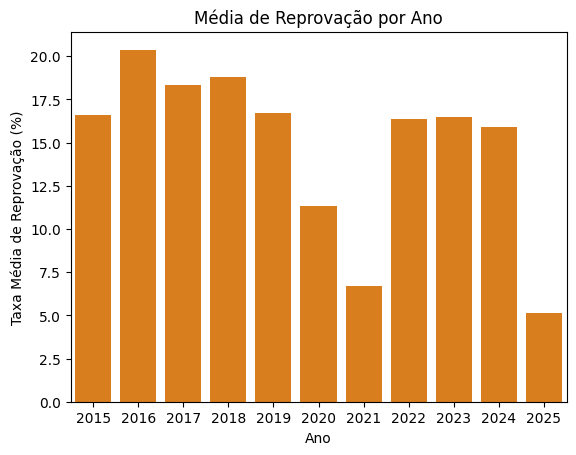

In [ ]:
#média de reprovação por ano
sns.barplot(reprovacao_por_ano, x='Ano_do_Censo', y='Reprovacao_EM_Total', color=CORES_TAXAS['Reprovação'])
plt.title('Média de Reprovação por Ano')
plt.xlabel('Ano')
plt.ylabel('Taxa Média de Reprovação (%)')
plt.show()

,Nome_do_Municipio,Ano_do_Censo,Abandono_EM_Total,Reprovacao_EM_Total,Aprovacao_EM_Total
0,MARICÁ,2015,5.325000,14.587500,80.087500
1,MARICÁ,2016,13.062500,12.212500,74.725000
2,MARICÁ,2017,2.688889,15.655556,81.655556
3,MARICÁ,2018,3.633333,13.866667,82.500000
4,MARICÁ,2019,6.800000,19.344444,73.855556
5,MARICÁ,2020,0.170000,3.180000,96.650000
6,MARICÁ,2021,1.360000,9.670000,88.970000
7,MARICÁ,2022,7.510000,12.940000,79.550000
8,MARICÁ,2023,8.170000,13.600000,78.230000
9,MARICÁ,2024,6.420000,17.680000,75.900000


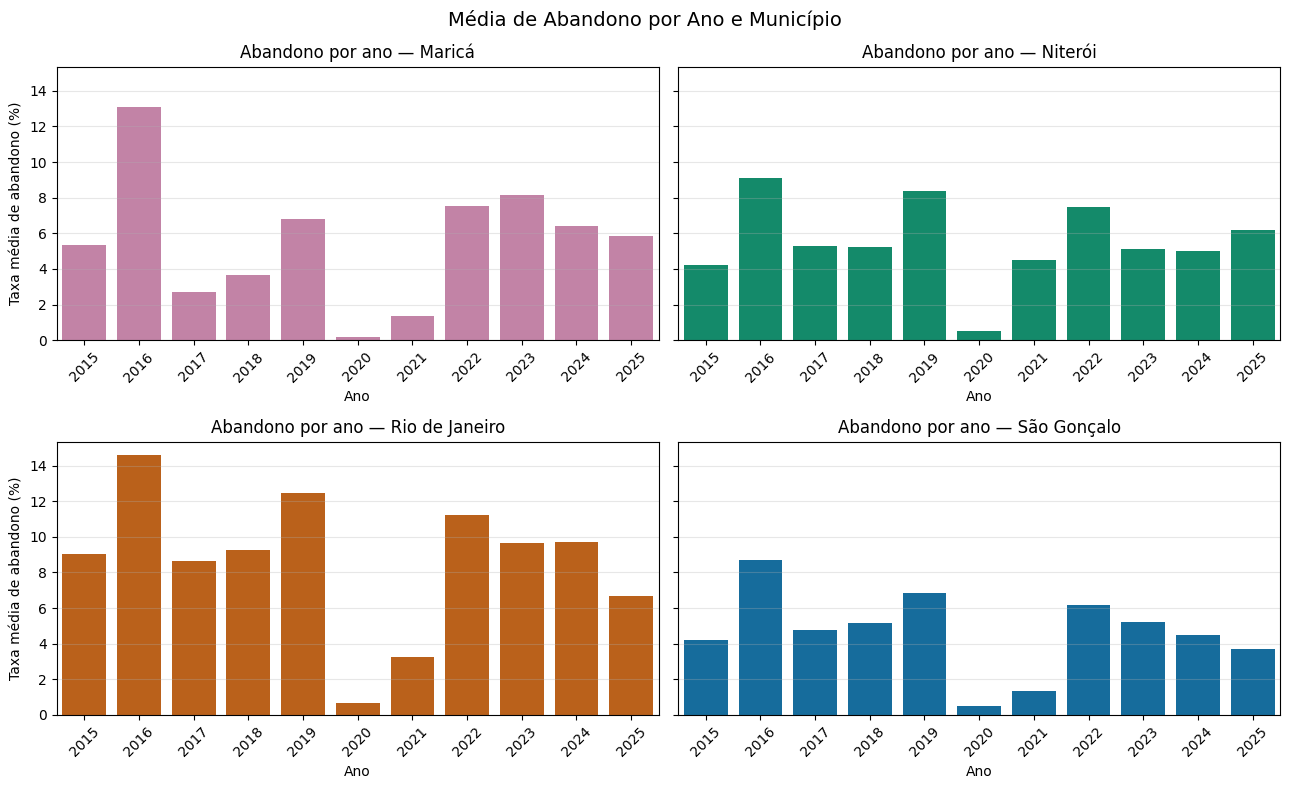

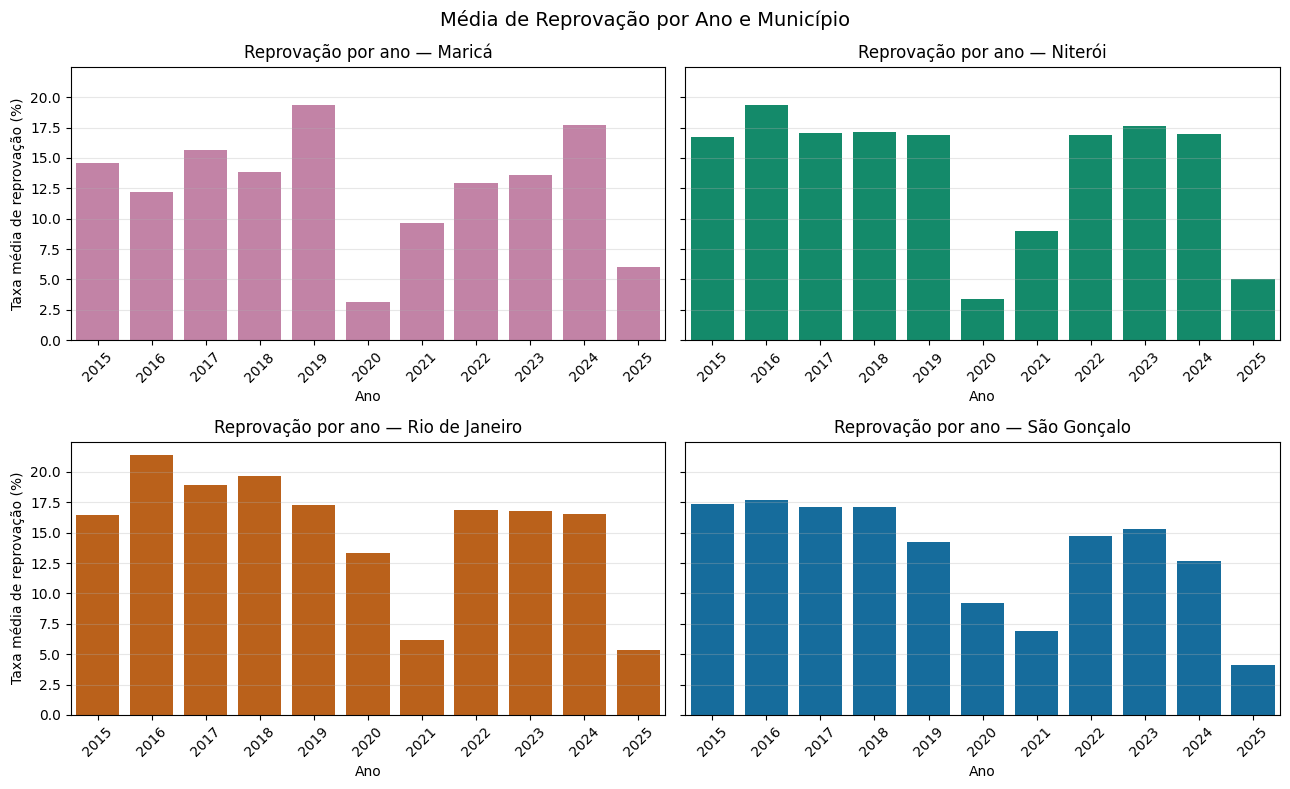

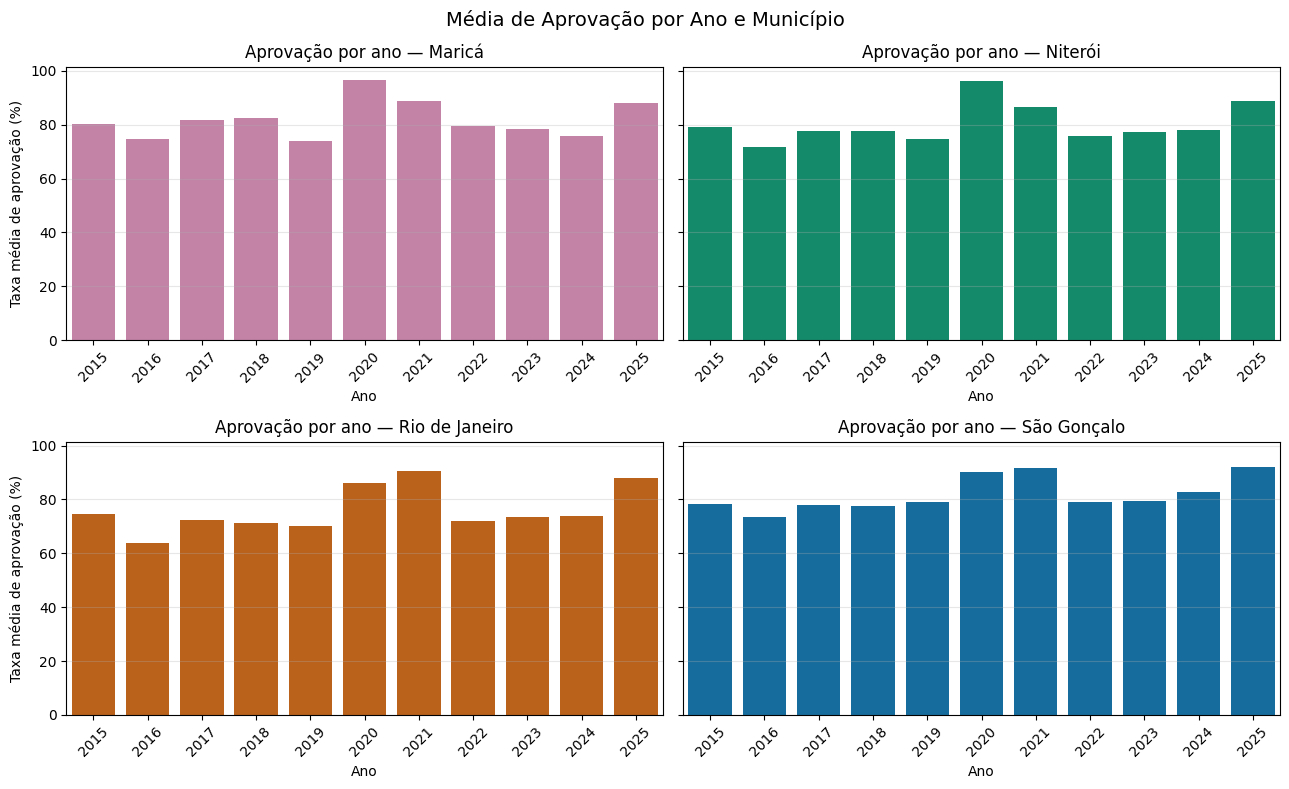

In [ ]:
# Médias por município e ano
indicadores = {
    'Abandono_EM_Total': 'Abandono',
    'Reprovacao_EM_Total': 'Reprovação',
    'Aprovacao_EM_Total': 'Aprovação'
}

media_cidade_ano = (
    df.groupby(['Nome_do_Municipio', 'Ano_do_Censo'])[list(indicadores)]
      .mean()
      .reset_index()
)
display(media_cidade_ano)

# Um painel 2x2 (uma cidade por quadro) para cada indicador
def grafico_por_cidade(coluna):
    nome = indicadores[coluna]
    cidades = sorted(media_cidade_ano['Nome_do_Municipio'].unique())
    fig, eixos = plt.subplots(2, 2, figsize=(13, 8), sharey=True)
    for ax, cidade in zip(eixos.flatten(), cidades):
        dados = media_cidade_ano[media_cidade_ano['Nome_do_Municipio'] == cidade]
        sns.barplot(data=dados, x='Ano_do_Censo', y=coluna, color=CORES_MUNICIPIOS[cidade], ax=ax)
        ax.set_title(f'{nome} por ano — {cidade.title().replace(" De ", " de ")}')
        ax.set_xlabel('Ano')
        ax.set_ylabel(f'Taxa média de {nome.lower()} (%)')
        ax.tick_params(axis='x', rotation=45)
        ax.grid(axis='y', alpha=0.3)
    plt.suptitle(f'Média de {nome} por Ano e Município', fontsize=14)
    plt.tight_layout()
    plt.show()

for coluna in indicadores:
    grafico_por_cidade(coluna)